In [1]:
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.express as px
import plotly.graph_objects as go
import dash
from dash import html, dcc
from dash.dependencies import Input, Output
import joblib
import scipy.stats as stats
from scipy.stats import pearsonr, shapiro
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from sklearn.linear_model import LinearRegression


df = pd.read_csv("data/advertising_and_sales.csv", index_col="id")

info_df = pd.DataFrame({
    "Tipo de dato": df.dtypes,
    "Registros no nulos": df.notnull().sum(),
    "Valores faltantes (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

display(Markdown("### Estructura y consistencia de los datos"))
display(info_df)
display(Markdown("-"*70))
display(Markdown("### Vista previa del DataFrame"))
display(df.head(10))

### Estructura y consistencia de los datos

,Tipo de dato,Registros no nulos,Valores faltantes (%)
tv,float64,4500,0.0
radio,float64,4500,0.0
social_media,float64,4500,0.0
influencer,object,4500,0.0
sales,float64,4500,0.0


----------------------------------------------------------------------

### Vista previa del DataFrame

,tv,radio,social_media,influencer,sales
id,,,,,
0,11124.31,6906.88,2907.98,Mega,26258.295
1,102.79,12676.45,2409.57,Mega,11709.120
2,45774.58,14914.53,2913.41,Mega,48345.630
3,65232.46,32016.26,6922.30,Mega,143851.565
4,11376.10,5490.95,1406.00,Micro,16816.820
5,40583.98,11999.30,1027.16,Mega,51321.760
6,54064.46,14125.79,4273.60,Micro,69624.320
7,30221.43,14291.12,2289.85,Nano,26573.295
8,60356.57,28263.00,7130.12,Macro,76668.675


### Resumen descriptivo: variables numéricas

,mean,std,min,50%,max,total
sales,72727.55,38195.62,7666.68,68635.57,180079.92,3.272740e+08
tv,54903.55,30135.93,33.97,52026.32,150940.95,2.470660e+08
radio,18321.51,11628.68,0.44,16297.64,71122.91,8.244678e+07
social_media,3335.74,2211.90,0.03,3070.61,13981.66,1.501084e+07


----------------------------------------------------------------------

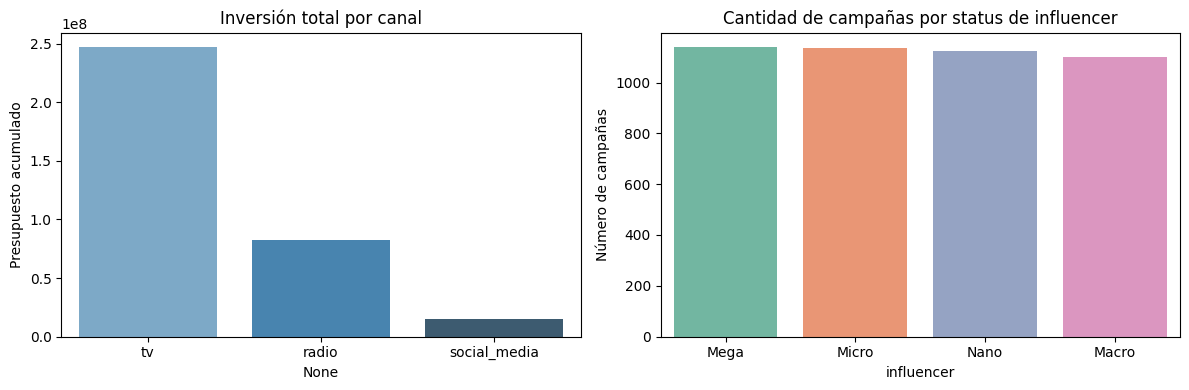

In [ ]:
numeric_cols = ["sales", "tv", "radio", "social_media"]

summary_num = df[numeric_cols].describe().T[["mean", "std", "min", "50%", "max"]]
summary_num["total"] = df[numeric_cols].sum()

display(Markdown("### Resumen descriptivo: variables numéricas"))
display(summary_num.round(2))
display(Markdown("-"*70))

category_col = "influencer"

frecuencies = pd.DataFrame({
    "Cantidad (absoluta)": df[category_col].value_counts(),
    "Porcentaje (%)": (df[category_col].value_counts(normalize=True) * 100).round(2)
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

total_investment = df[["tv", "radio", "social_media"]].sum()
sns.barplot(x=total_investment.index, y=total_investment.values, hue=total_investment.index, ax=axes[0], palette="Blues_d", legend=False)
axes[0].set_title("Inversión total por canal")
axes[0].set_ylabel("Presupuesto acumulado")

sns.countplot(data=df, x=category_col, hue=category_col, ax=axes[1], palette="Set2", legend=False)
axes[1].set_title("Cantidad de campañas por status de influencer")
axes[1].set_ylabel("Número de campañas")

plt.tight_layout()
plt.show()

#### Análisis Exploratorio de Datos: determinar patrones y concluir hipótesis

Seguidamente se explora el comportamiento de los datos donde el objetivo es descubrir patrones ocultos, anomalías, relaciones entre variables y errores que guíen la implementación de un modelo particular como solución. En un caso de regresión lineal con resultados fiables y en base a los primeros resultados, se deben cumplir los siguientes supuestos fundamentales:

**i) Linealidad**: La relación entre la variable independiente (𝑋) y la variable dependiente (𝑌) debe ser lineal. Esto significa que el cambio en 𝑌 por cada unidad de cambio en (𝑋) es constante. En una regresión lineal simple, el signo de β siempre coincidirá con el de 𝒓, sin embargo, en una regresión múltiple, los parámetros Beta se ajustan para controlar el efecto de las demás variables, aislando el impacto neto y evitando duplicar varianza compartida. Para compararlos directamente con la correlación, se deben utilizar Betas estandarizados ($Z-Score$), lo que elimina el sesgo de las diferentes escalas de medición.

**ii) Multicolinealidad**: No deben haber relaciones fuertemente lineales entre las variables predictoras debido las siguientes consecuencias: errores estándar elevedos, pérdida de signifancia y dificultad para aislar efectos.

**iii) ANOVA**: Evalúa si existen diferencias estadísticamente significativas entre las medias de la variable dependiente  a través de las distintas clases o categorías del predictor. Parte siempre de la premisa inicial de que las categorías evaluadas no aportan ninguna información nueva ni relevante; es decir, asume que las medias de ventas son estadísticamente iguales entre todos los grupos (Micro, Macro, Mega). Solo si el valor $p$ (PR>F) es inferior a 0.05, se rechaza esta suposición.

**iv) Outliers**: No es estrictamente un supuesto teórico sino más bien un requisito práctico de diagnóstico, ya que detectar casos atípicos en la relación lineal generada permite observar los valores influyentes que distorsionan significativamente la pendiente de la línea de regresión.

/tmp/ipykernel_821/1531175066.py:28: IterationLimitWarning: Maximum number of iterations (5000) reached.
  high_quantile = smf.quantreg("Sales ~ TV", df_temp).fit(q=0.975, max_iter=5000, method="asdf")


### i) Correlación de Pearsonr (Variable Y)

,TV,Radio,Social_Media
𝑟 (sales),0.770000,0.650000,0.470000
β (Z score),0.582863,0.256744,0.256744


----------------------------------------------------------------------

### ii) Análisis de Multicolineadad (Heatmap)

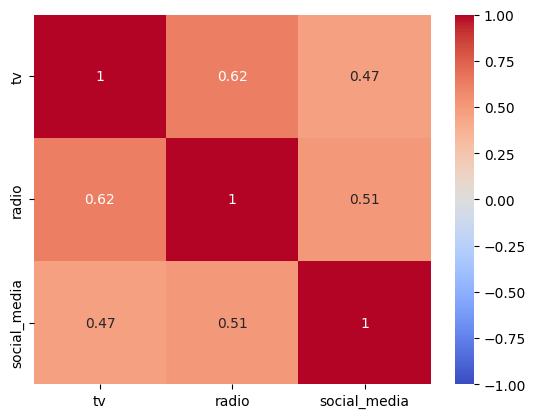

----------------------------------------------------------------------

### iii) Test de ANOVA (Variable Influencer)

,sum_sq,df,F,PR(>F)
influencer,1.341422e+09,3.0,0.306349,0.820827
Residual,6.562275e+12,4496.0,NaN,NaN


----------------------------------------------------------------------

### iv) Detección de outliers

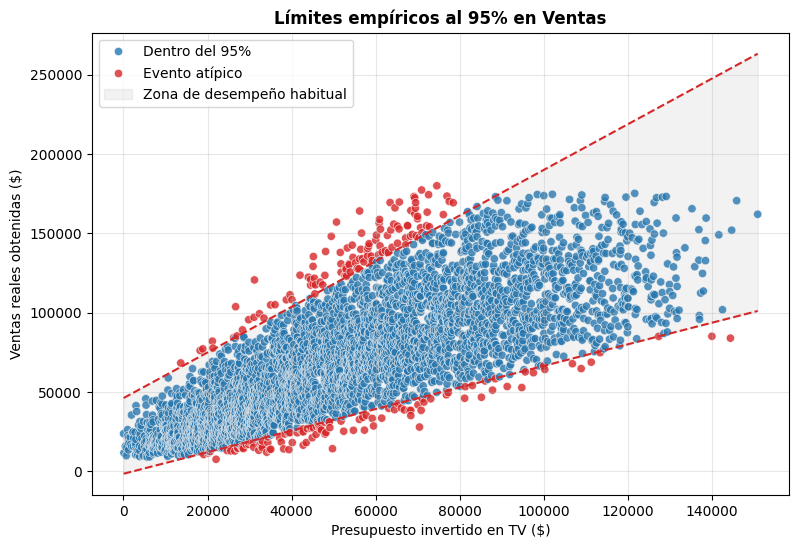

In [2]:
corr_tv, _ = pearsonr(df["tv"], df["sales"])
corr_radio, _ = pearsonr(df["radio"], df["sales"])
corr_social_media, _ = pearsonr(df["social_media"], df["sales"])

cols_corr = ["sales", "tv", "radio", "social_media"]
df_z = df[cols_corr].apply(stats.zscore)

model = smf.ols("sales ~ tv + radio + social_media", data=df_z).fit()
b1, b2, b3 = model.params.iloc[1], model.params.iloc[2], model.params.iloc[3]

data = {
   "TV": [round(corr_tv, 2), b1],
   "Radio": [round(corr_radio, 2), b2],
   "Social_Media": [round(corr_social_media, 2), b2]
}
df_measures  = pd.DataFrame(data, index=["𝑟 (sales)", "β (Z score)"])

haetmap = sns.heatmap(df[cols_corr[1:]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)

model2 = smf.ols("sales ~ influencer", data=df).fit()
anova_table = sm.stats.anova_lm(model2, typ=2)

x_data = df["tv"]
y_data = df["sales"]
df_temp = pd.DataFrame({"TV": x_data, "Sales": y_data}).sort_values(by="TV")

low_quantile = smf.quantreg("Sales ~ TV", df_temp).fit(q=0.025, max_iter=5000, method="asdf")
high_quantile = smf.quantreg("Sales ~ TV", df_temp).fit(q=0.975, max_iter=5000, method="asdf")

df_temp["limit_inf"] = low_quantile.predict(df_temp)
df_temp["limit_sup"] = high_quantile.predict(df_temp)

out_values = (df_temp["Sales"] < df_temp["limit_inf"]) | (df_temp["Sales"] > df_temp["limit_sup"])
df_temp["Status"] = "Dentro del 95%"
df_temp.loc[out_values, "Status"] = "Evento atípico"

display(Markdown("### i) Correlación de Pearsonr (Variable Y)"))
display(df_measures)
display(Markdown("-"*70))

display(Markdown("### ii) Análisis de Multicolineadad (Heatmap)"))
plt.show()
display(Markdown("-"*70))

display(Markdown("### iii) Test de ANOVA (Variable Influencer)"))
display(anova_table)
display(Markdown("-"*70))

display(Markdown("### iv) Detección de outliers"))
plt.figure(figsize=(9, 6))
sns.scatterplot( data=df_temp, x="TV", y="Sales", hue="Status", palette={"Dentro del 95%": "#1f77b4", "Evento atípico": "#d62728", }, alpha=0.8)
plt.plot(df_temp["TV"], df_temp["limit_sup"],color="#d62728", linestyle="--")
plt.plot(df_temp["TV"], df_temp["limit_inf"],color="#d62728", linestyle="--")
plt.fill_between(df_temp["TV"], df_temp["limit_inf"], df_temp["limit_sup"], color="gray", alpha=0.1, label="Zona de desempeño habitual",)
plt.title("Límites empíricos al 95% en Ventas", fontsize=12, fontweight="bold")
plt.xlabel("Presupuesto invertido en TV ($)", fontsize=10)
plt.ylabel("Ventas reales obtenidas ($)", fontsize=10)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

#### Linear Regression: modelo log-log sesgado por eficiencia
Antes de proceder con el desarrollo e implementación del simulador estratégico de reasignación de presupuesto publicitario —diseñado para proyectar el impacto económico en los ingresos y el retorno de inversión (ROI) y sirviendo para futuras estrategias—, se ejecutará una fase preliminar de logaritmos (relaciones no lineales) y validación estocástica donde el objetivo principal es probar la viabilidad del pipeline de datos utilizando un Modelo de Regresión Lineal Simple de base. Este modelo de prueba actuará como benchmark inicial y estará intencionalmente sesgado bajo una hipótesis de optimización heurística: evaluar el comportamiento del sistema ante un escenario teórico que asume un incremento del 12% en el ROI histórico.

Para aislar el efecto del canal publicitario de mayor impacto histórico y reducir el ruido en esta fase beta, el modelo matemático se acotará a la interacción de dos variables continuas específicas:
*   Variable Independiente ($Log(X)$): Logaritmo del presupuesto invertido en el canal de Televisión (TV Costs).
*   Variable Dependiente ($Log(Y)$): Logaritmo de los ingresos brutos generados por las respectivas ventas (Sales Revenues).

Donde el coeficiente $\beta_1$ de la ecuación incorporará directamente el factor de sesgo controlado del +12% sobre la pendiente histórica promedio, permitiendo simular el estrés del modelo ante este cambio en las condiciones económicas antes de escalar la arquitectura de software.

In [ ]:
df["ROI"] = (df["sales"] - df["tv"]) / df["tv"]
df_efficient = df[df["ROI"] >= df["ROI"].quantile(0.12)].copy()

df_efficient["tv_log"] = np.log1p(df_efficient["tv"])
df_efficient["sales_log"] = np.log1p(df_efficient["sales"])

index = np.arange(len(df_efficient))
np.random.seed(42)
np.random.shuffle(index)

X = df_efficient["tv_log"].values.reshape((-1, 1))[index]
y = df_efficient["sales_log"].values[index]

limit = int(0.8 * len(X))

X_train, X_test = X[:limit], X[limit:]
y_train, y_test = y[:limit], y[limit:]

model_linear_regression = LinearRegression()
model_linear_regression.fit(X_train, y_train)

y_pred_test = model_linear_regression.predict(X_test)

B1 = model_linear_regression.coef_[0]
r2 = r2_score(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

mape = (mean_absolute_percentage_error(y_test, y_pred_test))*100
mape = np.expm1(mape)

residuals = y_test - y_pred_test
stat, p_val = shapiro(residuals)
norm_residuals = p_val > 0.05

df_log = np.log(df[["tv", "radio", "social_media", "sales"]] + 1)
elasticity_roi_advertising = LinearRegression()
elasticity_roi_advertising.fit(df_log[["tv", "radio", "social_media"]], df_log["sales"])
joblib.dump(elasticity_roi_advertising, "elasticity_roi_advertising.pkl")

display(Markdown("#### --- RESULTADOS DE VALIDACIÓN DEL MODELO ---"))
print(f"Coeficiente de Determinación (R²): {round(r2, 4)}")
print(f"Raíz del Error Cuadrático Medio (RMSE): ${round(rmse, 2)}")
print(f"Error Absoluto Medio Porcentual (MAPE): {round(mape, 2)}%")
print(f"Normalidad de Residuos (Shapiro-Wilk): p-valor = {p_val:.4e} -> {"PASÓ" if norm_residuals else "FALLÓ"}")
print("-"*100)
print(f"Interpretación: Un aumento del 1% en la inversión se traduce en un aumento de {round(B1*100, 2)}$. El modelo explica el {round(r2*100, 2)}% de la variación en ventas.")
if r2 > 0.7 and mape < 10.0  and norm_residuals:
    print("Estado: MODELO VALIDADO PARA PRODUCCIÓN (EXCELENTE) - Alta precisión y residuos normales pero sin homocedasticidad.")
elif r2 > 0.7 and mape < 10.0 and not norm_residuals:
    print("Estado: MODELO VALIDADO PARA PRODUCCIÓN (APROBADO) - Alta precisión pero sin residuos normales y sin homocedasticidad.")
else:
    print("Estado: REVISAR SEGMENTACIÓN - Precisión por debajo del umbral objetivo.")

#### --- RESULTADOS DE VALIDACIÓN DEL MODELO ---

Coeficiente de Determinación (R²): 0.7141
Raíz del Error Cuadrático Medio (RMSE): $0.32
Error Absoluto Medio Porcentual (MAPE): 8.95%
Normalidad de Residuos (Shapiro-Wilk): p-valor = 1.1798e-09 -> FALLÓ
----------------------------------------------------------------------------------------------------
Interpretación: Un aumento del 1% en la inversión se traduce en un aumento de 66.81$. El modelo explica el 71.41% de la variación en ventas.
Estado: MODELO VALIDADO PARA PRODUCCIÓN (APROBADO) - Alta precisión pero sin residuos normales y sin homocedasticidad.


#### Herramienta interactiva de optimización estratégica basado en la frontera de eficiencia presupuestaria

In [ ]:
elasticities = dict(zip(["TV", "Radio", "Social Media"], elasticity_roi_advertising.coef_))
mean_margin = df["sales"].mean() - (df["tv"].mean() + df["radio"].mean() + df["social_media"].mean())

app = dash.Dash(__name__)

app.layout = html.Div(id="body", className="e2_body", children=[
    html.H1("Estrategia de Inversión: del volumen a la rentabilidad", className="e2_title"),

    html.Div(className="e2_div_stats", children=[
        html.Div([html.H3("Margen Neto Promedio"), html.P(f"${round(mean_margin, 2)}", style={"font-weight":"bold","font-size":"1.2em"})], className="e2_stats"),
        html.Div([html.H3("Elasticidad TV (Dominancia)"), html.P(f"{round(elasticities["TV"], 2)}", style={"font-weight":"bold","font-size":"1.2em"})], className="e2_stats"),
        html.Div([html.H3("Elasticidad Radio (Oportunidad)"), html.P(f"{round(elasticities["Radio"], 2)}", style={"font-weight":"bold","font-size":"1.2em"})], className="e2_stats"),
    ]),

    html.Div(id="dashboard", className="e2_dashboard", children=[
         html.Div(className="e2_column_1", children=[
             html.Div(className="e2_div_graphs", children=[
                 dcc.Graph(id="graph-pie", className="e2_graphs", figure={}),
                 dcc.Graph(id="graph-bar", className="e2_graphs", figure={})
             ]),

             html.Div(className="e2_div_slider", children=[
                html.Label("Simulador de Rebalanceo: Mover presupuesto de TV a Radio (%)", className="e2_label"),
                dcc.Slider(
                    id="rebalance-slider",
                    min=0, max=30, step=5, value=0,
                    marks={i: {"label": f"{i}%", "style": {"color": "white"}} for i in range(0, 31, 5)}
                )
            ])
        ]),

        html.Div(className="e2_column_2", children=[
           dcc.Graph(id="graph-scatter"),
           html.Div(id="text-resolution", className="e2_text_resolution")
        ])
    ])
])


@app.callback(
    [Output(component_id="graph-pie",component_property="figure"),
    Output(component_id="graph-bar",component_property="figure"),
    Output(component_id="graph-scatter",component_property="figure"),
    Output(component_id="text-resolution",component_property="children")],
   [Input(component_id="rebalance-slider",component_property="value")]
)

def update_strategy(rebalance_pct):
    cost_tv_orig = df["tv"].mean()
    money_change = cost_tv_orig * (rebalance_pct / 100)

    piechart = go.Figure(data=[go.Pie(labels=["TV", "Radio", "RRSS"], values=[df["tv"].mean(), df["radio"].mean(), df["social_media"].mean()])])
    piechart.update_layout(title="Distribución Actual del Gasto")

    barchart = go.Figure([go.Bar(x=list(elasticities.keys()), y=list(elasticities.values()), marker_color="indigo")])
    barchart.update_layout(title="Elasticidad: Sensibilidad de Ventas al +1% Gasto", yaxis_title="Impacto % en Ventas")

    scatter = go.Figure()
    scatter.add_trace(go.Scatter(x=df["tv"], y=df["sales"], mode="markers", name="Campaña Estándar", opacity=0.4))
    scatter.add_trace(go.Scatter(x=df_efficient["tv"], y=df_efficient["sales"], mode="markers", name="Frontera de Eficiencia", marker=dict(color="green", size=8)))
    scatter.update_layout(title="Identificación de la Frontera de Eficiencia", xaxis_title="Gasto TV", yaxis_title="Ventas")

    sales_est = df["sales"].mean() * (1 + (rebalance_pct/100 * elasticities["Radio"]))
    text = [
        html.H4("Resolución Estratégica:"),
        html.P(f"Al rebalancear un {rebalance_pct}% de TV hacia Radio, estás moviendo ${round(money_change, 2)} a un canal con mayor retorno marginal."),
        html.P(f"Estimación: Las ventas podrían optimizarse un {round(rebalance_pct * elasticities["Radio"], 2)}% manteniendo el presupuesto constante.")
    ]

    return piechart, barchart, scatter, text

if __name__ == "__main__":
    app.run(debug=False)